In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.aa_nnls import archetypal_analysis as aa_nnls_analysis
from src.aagradient import archetypal_analysis as gradient_analysis
# from src.biaa import biarchetypal_analysis
from src.Weighted import weighted_archetypal_analysis

np.set_printoptions(precision=4, suppress=True)

In [2]:
# Datos con menor separación entre arquetipos y adición de ruido
rng = np.random.default_rng(42)

# Arquetipos verdaderos más cercanos entre sí
true_Z = np.array([
    [0.0, 0.0],
    [0.4, 0.05],
    [0.15, 0.45]
])

n_samples = 150
true_S = rng.dirichlet(np.ones(3), size=n_samples)
X = true_S @ true_Z

# Añadir ruido gausiano
X += rng.normal(0, 0.02, size=X.shape)

p = 3

# Definir tres niveles de pesos basados en la distancia al tercer arquetipo
distances = np.linalg.norm(X - true_Z[2], axis=1)

# Dividimos las distancias en tres grupos ordenados
idx_sorted = np.argsort(distances)
group_size = n_samples // 3

weights = np.ones(n_samples)
# Grupo más cercano: peso menor
weights[idx_sorted[:group_size]] = 0.7
# Grupo intermedio: peso moderado
weights[idx_sorted[group_size:2*group_size]] = 0.85
# Grupo más lejano: peso completo
weights[idx_sorted[2*group_size:]] = 1.0

W = np.diag(weights)

print("Dimensiones de X:", X.shape)
print("Número de arquetipos p:", p)
print("Puntos con peso 1.0:", np.sum(weights == 1.0))
print("Puntos con peso 0.85:", np.sum(weights == 0.85))
print("Puntos con peso 0.7:", np.sum(weights == 0.7))

Dimensiones de X: (150, 2)
Número de arquetipos p: 3
Puntos con peso 1.0: 50
Puntos con peso 0.85: 50
Puntos con peso 0.7: 50


In [3]:
# Métodos
# A) AA-NNLS sin ponderar
A_nnls, B_nnls, Z_nnls, Z0_nnls, rss_nnls = aa_nnls_analysis(
    X, p=p, max_iter=100, max_inner_iter=100, tol=1e-8
)

# B) AA-gradient sin ponderar
C_grad, S_grad, Z_grad, hist_grad, selected_grad = gradient_analysis(
    X, p=p, max_iter=100, max_inner_iter=10, tol=1e-8,
    random_state=42, verbose=False
)

# C) AA-gradient ponderado
C_wgrad, S_wgrad, Z_wgrad, hist_wgrad, selected_wgrad = gradient_analysis(
    W @ X, p=p, max_iter=100, max_inner_iter=10, tol=1e-8,
    random_state=42, verbose=False
)

# D) AA-NNLS ponderado (usando aa_nnls_analysis con W @ X)
A_wnnls, B_wnnls, Z_wnnls, Z0_wnnls, rss_wnnls = aa_nnls_analysis(
    W @ X, p=p, max_iter=100, max_inner_iter=100, tol=1e-8
)

# E) biAA: análisis complementario con su parametrización propia
# alpha_bi, beta_bi, gamma_bi, theta_bi, Z_bi, rss_bi = biarchetypal_analysis(
#     X, k=3, c=2, max_iter=100, tol=1e-5, seed=42, verbose=False
# )

# F) AA-gradient ponderado según el artículo (reutilizando preprocesamiento y postprocesamiento optimizado)
C_wgrad_art, S_wgrad_art, Z_wgrad_art, hist_wgrad_art, selected_wgrad_art = weighted_archetypal_analysis(
    X, p=p, W=weights, max_iter=100, max_inner_iter=10, tol=1e-8,
    random_state=42, verbose=False
)

print("Ejecución completada.")

Iteration 1: RSS = 1.022613, improvement = inf
Iteration 2: RSS = 0.578308, improvement = 0.444305
Iteration 3: RSS = 0.497112, improvement = 0.081197
Iteration 4: RSS = 0.457381, improvement = 0.039730
Iteration 5: RSS = 0.357305, improvement = 0.100076
Iteration 6: RSS = 0.208526, improvement = 0.148779
Iteration 7: RSS = 0.100881, improvement = 0.107646
Iteration 8: RSS = 0.051013, improvement = 0.049867
Iteration 9: RSS = 0.032522, improvement = 0.018491
Iteration 10: RSS = 0.027787, improvement = 0.004735
Iteration 11: RSS = 0.024947, improvement = 0.002840
Iteration 12: RSS = 0.022954, improvement = 0.001993
Iteration 13: RSS = 0.021511, improvement = 0.001443
Iteration 14: RSS = 0.020462, improvement = 0.001049
Iteration 15: RSS = 0.019689, improvement = 0.000772
Iteration 16: RSS = 0.019108, improvement = 0.000581
Iteration 17: RSS = 0.018662, improvement = 0.000446
Iteration 18: RSS = 0.018312, improvement = 0.000350
Iteration 19: RSS = 0.018031, improvement = 0.000281
Iterati

In [4]:
# Comparación cuantitativa de los métodos
def sse(X_true, X_hat):
    return float(np.sum((X_true - X_hat) ** 2))

def weighted_sse(X_true, X_hat, w):
    # Pesos por observación: cada residuo de fila se multiplica por w_i.
    return float(np.sum(w[:, None] * (X_true - X_hat) ** 2))

Xhat_nnls = A_nnls @ Z_nnls
Xhat_grad = S_grad @ Z_grad
Xhat_wgrad = S_wgrad @ Z_wgrad
Xhat_wnnls = A_wnnls @ Z_wnnls
# Xhat_bi = alpha_bi @ Z_bi @ gamma_bi
Xhat_art = S_wgrad_art @ Z_wgrad_art

results = [
    {"Método": "AA-NNLS", "Ponderado": "No", "SSE común": sse(X, Xhat_nnls),
     "SSE ponderado": weighted_sse(X, Xhat_nnls, weights), "Iteraciones/loss final": rss_nnls},
    {"Método": "AA-gradient", "Ponderado": "No", "SSE común": sse(X, Xhat_grad),
     "SSE ponderado": weighted_sse(X, Xhat_grad, weights), "Iteraciones/loss final": hist_grad[-1]},
    {"Método": "AA-gradient Ponderado", "Ponderado": "Sí", "SSE común": sse(X, Xhat_wgrad),
     "SSE ponderado": weighted_sse(X, Xhat_wgrad, weights), "Iteraciones/loss final": hist_wgrad[-1]},
    {"Método": "AA-NNLS Ponderado", "Ponderado": "Sí", "SSE común": sse(X, Xhat_wnnls),
     "SSE ponderado": weighted_sse(X, Xhat_wnnls, weights), "Iteraciones/loss final": rss_wnnls},
    # {"Método": "biAA", "Ponderado": "No aplica", "SSE común": sse(X, Xhat_bi),
    #  "SSE ponderado": weighted_sse(X, Xhat_bi, weights), "Iteraciones/loss final": rss_bi},
    {"Método": "AA-gradient Ponderado (Artículo)", "Ponderado": "Sí", "SSE común": sse(X, Xhat_art),
     "SSE ponderado": weighted_sse(X, Xhat_art, weights), "Iteraciones/loss final": hist_wgrad_art[-1]},
]

comparison = pd.DataFrame(results)
display(comparison.round(6))

,Método,Ponderado,SSE común,SSE ponderado,Iteraciones/loss final
0,AA-NNLS,No,0.017567,0.016694,0.017567
1,AA-gradient,No,0.021848,0.020416,0.021848
2,AA-gradient Ponderado,Sí,0.603159,0.445716,0.037896
3,AA-NNLS Ponderado,Sí,0.572992,0.418084,0.017812
4,AA-gradient Ponderado (Artículo),Sí,0.362199,0.272360,0.037896


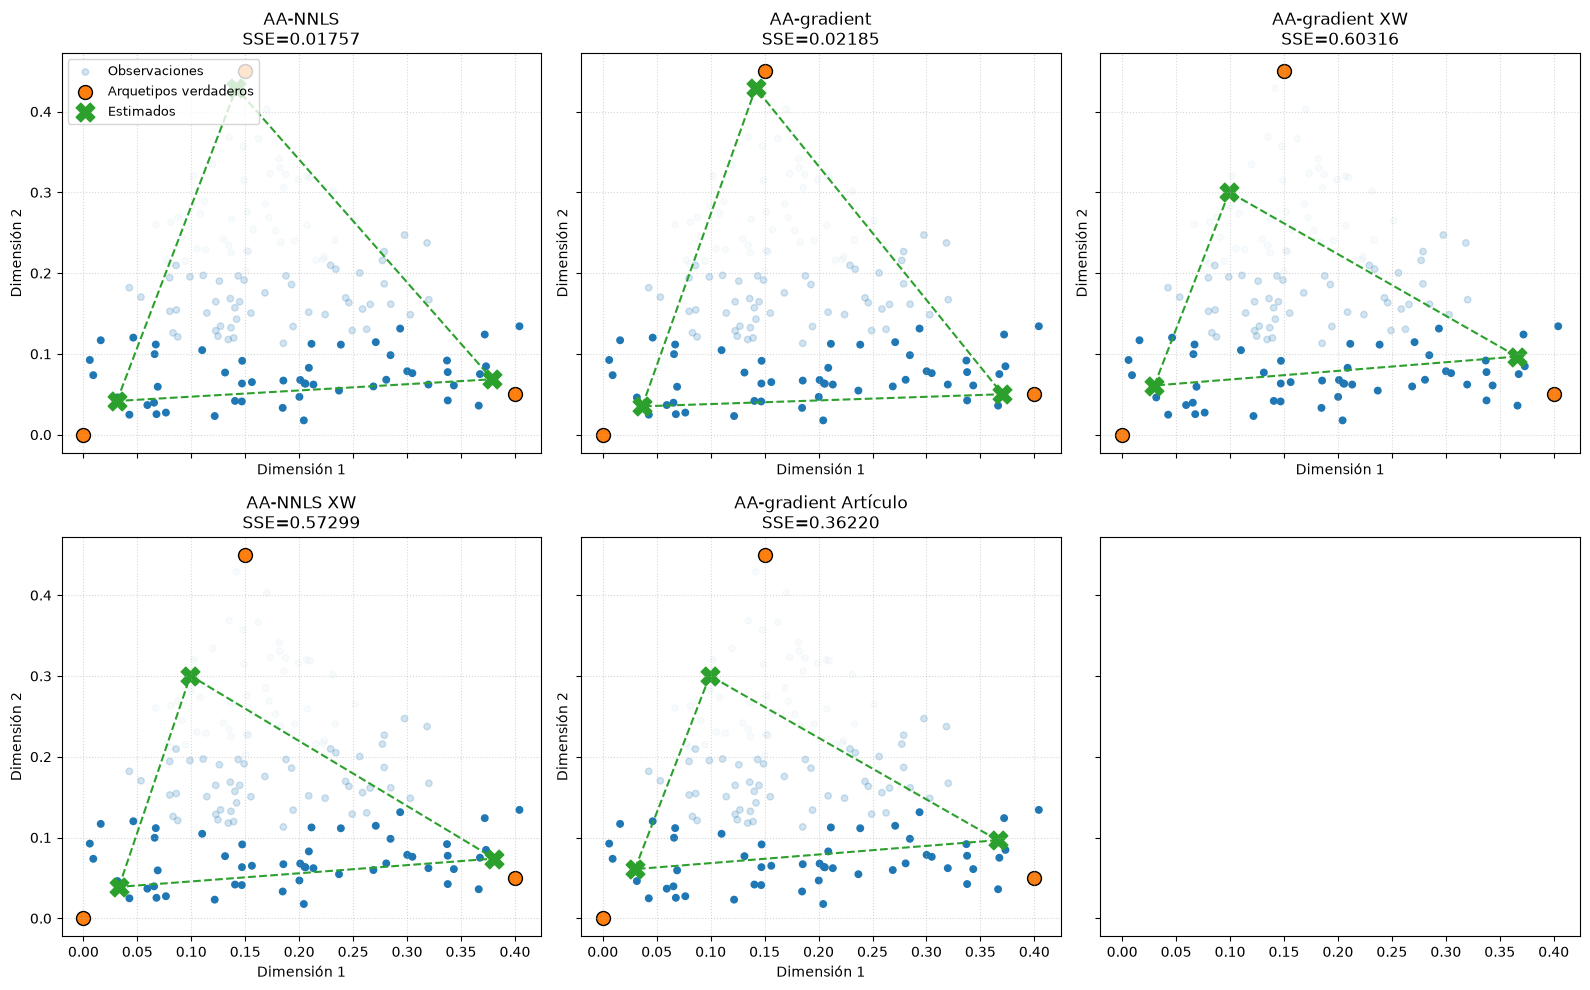

In [5]:
# Comparación visual de los métodos
Xhat_by_name = {
    "AA-NNLS": Xhat_nnls,
    "AA-gradient": Xhat_grad,
    "AA-gradient XW": Xhat_wgrad,
    "AA-NNLS XW": Xhat_wnnls,
    # "biAA": Xhat_bi,
    "AA-gradient Artículo": Xhat_art,
}

Z_by_name = {
    "AA-NNLS": Z_nnls,
    "AA-gradient": Z_grad,
    "AA-gradient XW": Z_wgrad,
    "AA-NNLS XW": Z_wnnls,
    # "biAA": Z_bi,
    "AA-gradient Artículo": Z_wgrad_art,
}

fig, axes = plt.subplots(
    2, 3, figsize=(16, 10), sharex=True, sharey=True
)

axes_flat = axes.ravel()

for i, (name, Z_est) in enumerate(Z_by_name.items()):
    ax = axes_flat[i]

    # Mostrar punts observats amb opacitat/mida proporcional al seu pes
    ax.scatter(
        X[:, 0], X[:, 1],
        s=22, alpha=weights**10, label="Observaciones"
    )

    # Arquetipus reals
    ax.scatter(
        true_Z[:, 0], true_Z[:, 1],
        s=100, marker="o", edgecolors="black",
        label="Arquetipos verdaderos"
    )

    # Arquetipus estimats
    ax.scatter(
        Z_est[:, 0], Z_est[:, 1],
        s=180, marker="X", label="Estimados"
    )

    poly = np.vstack([Z_est, Z_est[0]])
    ax.plot(poly[:, 0], poly[:, 1], "--", color="tab:green",linewidth=1.5)

    ax.set_title(f"{name}\nSSE={sse(X, Xhat_by_name[name]):.5f}")
    ax.set_xlabel("Dimensión 1")
    ax.set_ylabel("Dimensión 2")
    ax.grid(True, linestyle=":", alpha=0.5)

# Colocamos la leyenda en el primer subplot para no saturar
axes.ravel()[0].legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()